<a href="https://colab.research.google.com/github/nivethashrikm08-blip/MLA0202-FML/blob/main/ML%203.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Prediction for new sample: No


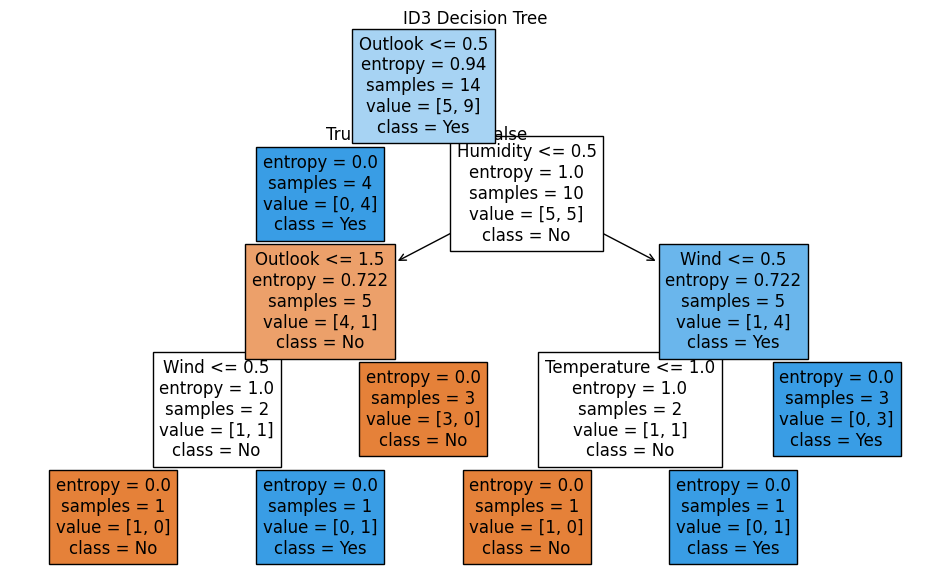

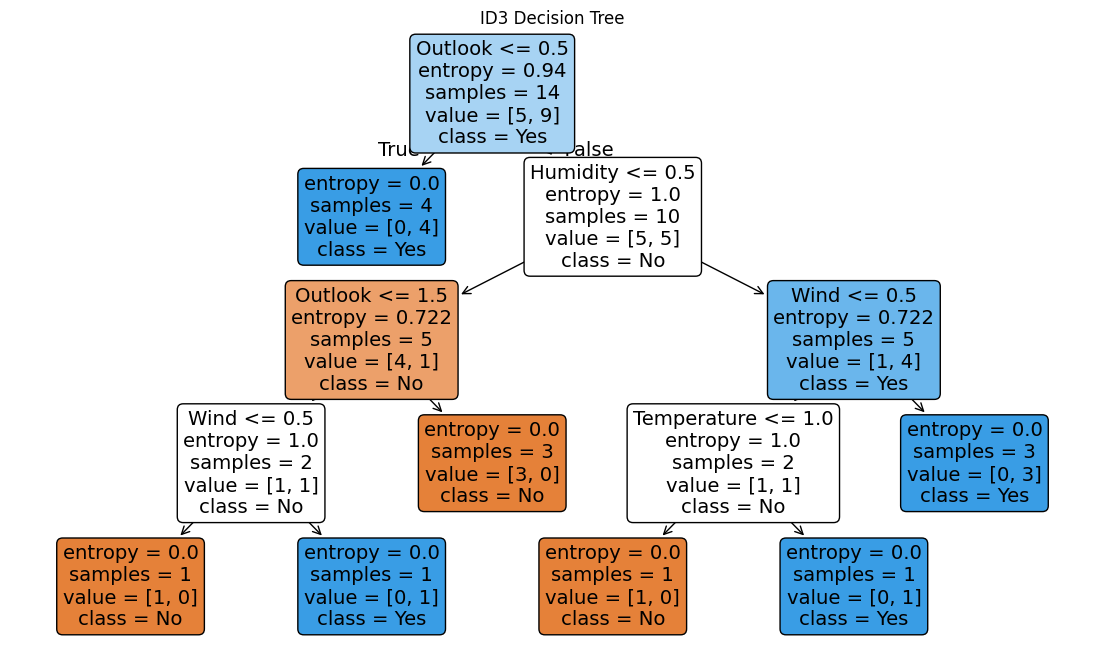

In [1]:
# ID3 Decision Tree

import pandas as pd
import matplotlib.pyplot as plt
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.preprocessing import LabelEncoder

data = pd.DataFrame({
    "Outlook": ["Sunny", "Sunny", "Overcast", "Rain",
                "Rain", "Rain", "Overcast", "Sunny",
                "Sunny", "Rain", "Sunny", "Overcast",
                "Overcast", "Rain"],
    "Temperature": ["Hot", "Hot", "Hot", "Mild",
                    "Cool", "Cool", "Cool", "Mild",
                    "Cool", "Mild", "Mild", "Mild",
                    "Hot", "Mild"],
    "Humidity": ["High", "High", "High", "High",
                 "Normal", "Normal", "Normal", "High",
                 "Normal", "Normal", "Normal", "High",
                 "Normal", "High"],
    "Wind": ["Weak", "Strong", "Weak", "Weak",
             "Weak", "Strong", "Strong", "Weak",
             "Weak", "Weak", "Strong", "Strong",
             "Weak", "Strong"],
    "Play": ["No", "No", "Yes", "Yes", "Yes", "No",
             "Yes", "No", "Yes", "Yes", "Yes", "Yes",
             "Yes", "No"]
})

X = data.drop("Play", axis=1)
y = data["Play"]

# Convert text values into numbers
encoders = {}

for col in X.columns:
    encoders[col] = LabelEncoder()
    X[col] = encoders[col].fit_transform(X[col])

model = DecisionTreeClassifier(
    criterion="entropy",
    random_state=0
)
model.fit(X, y)

# Classify a new sample
sample = {
    "Outlook": "Sunny",
    "Temperature": "Cool",
    "Humidity": "High",
    "Wind": "Strong"
}

new_sample = pd.DataFrame([sample])

for col in new_sample.columns:
    new_sample[col] = encoders[col].transform(new_sample[col])

prediction = model.predict(new_sample)

print("Prediction for new sample:", prediction[0])

# Draw the decision tree
plt.figure(figsize=(12, 7))
plot_tree(
    model,
    feature_names=X.columns,
    class_names=model.classes_,
    filled=True
)
plt.title("ID3 Decision Tree")
plt.show()
import matplotlib.pyplot as plt
from sklearn.tree import plot_tree

plt.figure(figsize=(14, 8))

plot_tree(
    model,
    feature_names=X.columns,
    class_names=model.classes_,
    filled=True,
    rounded=True
)

plt.title("ID3 Decision Tree")
plt.show()